# 03 · Cross-check against Owl

[Owl](https://github.com/mdlacasse/Owl) (`pip install owlplanner`) is an independent,
open-source retirement optimizer. It solves a linear program over the whole plan: withdrawals
from each account, taxes, Social Security taxability, RMDs. This notebook runs the same
fictional household through both tools for every historical start year and compares one
number per cohort: **the highest flat after-tax spending that lasts to 95 with nothing left**.

This is a test of the engine, not a recommendation. Agreement means the cash-flow, tax and
return plumbing produce similar answers when they are given the same problem.

*Educational software, not financial advice.* Requires the `notebooks` extra
(`pip install -e ".[notebooks]"`). Runtime is about a minute, almost all of it Owl's
solver (one linear program per start year).

## The household and the assumptions both tools share

The library's fictional default couple, both 50, plan to 95:

- $1,800,000 split 25% taxable / 60% tax-deferred / 15% Roth; half of the taxable balance is
  unrealized gain.
- 60% stocks / 40% 10-year Treasuries, rebalanced yearly; no fees.
- Pensions $24,000 (A, from 60) and $9,000 (B, from 65), fully indexed to inflation.
- Social Security: A $33,000 at FRA claimed at 67; B $26,000 at FRA claimed at 70.
- Federal tax only, married filing jointly. No state tax, no Medicare premiums, no Roth
  conversions, no bequest.
- Flat real spending.

Settings on the Owl side: `setSpendingProfile("flat")`, objective `maxSpending` with
`bequest=0`, `withMedicare="none"`, `maxRothConversion=0`, `setDividendRate(0)`, allocation
`[60, 0, 40, 0]` (S&P 500, Baa corporates, 10-year T-notes, cash), indexed pensions. Owl starts
its plans in the current calendar year, so the birth dates are set to make both people 50 in
the first plan year.

In [1]:
import datetime
import io
import time
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import owlplanner as owl
import pandas as pd

import firebridgelab as rm
from firebridgelab.engine.cohort_windows import cohort_return_sequences
from firebridgelab.spending import make_strategy
from firebridgelab.tax.location_path import simulate_dragged_depletion_only, year_tax_context_table

plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (9, 4.2)})
pd.set_option("display.width", 140)
print("firebridgelab", rm.__version__, "· owlplanner", owl.__version__)

firebridgelab 0.1.0 · owlplanner 2026.10.28


In [2]:
plan = replace(
    rm.default_scenario(),
    taxable_balance=450_000.0, tax_deferred_balance=1_080_000.0, roth_balance=270_000.0,
    taxable_gains_fraction=0.5,
)
assert plan.initial_portfolio == 1_800_000.0
HORIZON = plan.end_age - plan.start_age + 1     # 46 return-years, ages 50..95

THIS_YEAR = datetime.date.today().year

def owl_case():
    dob = f"{THIS_YEAR - plan.start_age}-01-02"
    p = owl.Plan(["A", "B"], [dob, dob], [plan.end_age, plan.end_age], "fictional couple",
                 verbose=False, logstreams=[io.StringIO()])
    p.setAccountBalances(taxable=[225, 225], taxDeferred=[540, 540], taxFree=[135, 135],
                         startDate=f"{THIS_YEAR}-01-01")           # $k, split evenly per person
    p.setCostBasis([112.5, 112.5])                               # 50% unrealized gain
    p.setPension([24_000 / 12, 9_000 / 12], [60, 65], indexed=[True, True])
    p.setSocialSecurity([33_000 / 12, 26_000 / 12], [67, 70])     # monthly PIAs, claim ages
    p.setSpendingProfile("flat", 100)
    p.setDividendRate(0)
    p.setAllocationRatios("spouses", generic=[[60, 0, 40, 0], [60, 0, 40, 0]])
    assert p.N_n == HORIZON
    return p

OWL_OPTIONS = {"maxRothConversion": 0, "bequest": 0, "withMedicare": "none"}

## Start years

Both tools need a full 46-year window of returns. Owl's table starts in 1928 and this
library's Shiller series ends in 2025, so the common range is 1928 to 2025 − 45 = 1980.
(With a shorter horizon the range would reach further; the 46-year horizon of a retirement at
50 is what limits it.)

In [3]:
rm_years, rm_returns = cohort_return_sequences(plan)
last_start = min(rm_years[-1], THIS_YEAR - HORIZON)
START_YEARS = list(range(1928, last_start + 1))
print(f"{len(START_YEARS)} start years: {START_YEARS[0]}–{START_YEARS[-1]}")

53 start years: 1928–1980


## Owl: one optimization per start year

In [4]:
t0 = time.time()
case = owl_case()
owl_spend = {}
for year in START_YEARS:
    case.setRates("historical", year)
    case.solve("maxSpending", OWL_OPTIONS)
    owl_spend[year] = case.basis if case.caseStatus == "solved" else np.nan
owl_spend = pd.Series(owl_spend, name="Owl")
print(f"Owl: {owl_spend.notna().sum()} of {len(START_YEARS)} solved in {time.time() - t0:.0f} s")

Owl: 53 of 53 solved in 7 s


## This library: bisection on the tax-dragged path

For each cohort, bisect on `annual_spending` (after-tax spending) for the largest value whose
**tax-dragged** path never depletes before 95. This is the same evaluator the library's
`solve_max_spend` uses when a tax-location split is set
(`simulate_dragged_depletion_only`), run one cohort at a time instead of as a survival
fraction. The library does not optimize withdrawal order: it draws taxable first, then
tax-deferred, then Roth, and taxes each year's withdrawals with 2026 federal brackets held
constant in real terms.

In [5]:
TAX_CONTEXT = year_tax_context_table(plan)

def survives(spend, returns):
    probe = replace(plan, annual_spending=spend)
    return simulate_dragged_depletion_only(probe, returns, make_strategy(probe),
                                           year_context=TAX_CONTEXT) is None

def max_flat_spend(returns, lo=0.0, hi=400_000.0, tol=10.0):
    while hi - lo > tol:
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if survives(mid, returns) else (lo, mid)
    return lo

t0 = time.time()
by_year = dict(zip(rm_years, rm_returns))
ours = pd.Series({y: max_flat_spend(by_year[y]) for y in START_YEARS}, name="this library")
print(f"this library: {len(ours)} cohorts in {time.time() - t0:.1f} s")

this library: 53 cohorts in 0.3 s


### A control: this library on Owl's return data

The two tools also use different return data. This library reads Shiller's January-to-January
series; Owl ships its own calendar-year table (S&P 500 total return, 10-year T-notes, CPI).
Feeding Owl's table through this library's engine separates the data difference from the
model difference.

In [6]:
from pathlib import Path
owl_rates = pd.read_csv(Path(owl.__file__).parent / "data" / "rates.csv").set_index("year")
def real(col):
    return (1 + owl_rates[col] / 100) / (1 + owl_rates["Inflation"] / 100) - 1
owl_blend = 0.6 * real("S&P 500") + 0.4 * real("T-Notes")
ours_on_owl_data = pd.Series(
    {y: max_flat_spend(owl_blend.loc[y:y + HORIZON - 1].to_numpy()) for y in START_YEARS},
    name="this library, Owl's data",
)

## Comparison

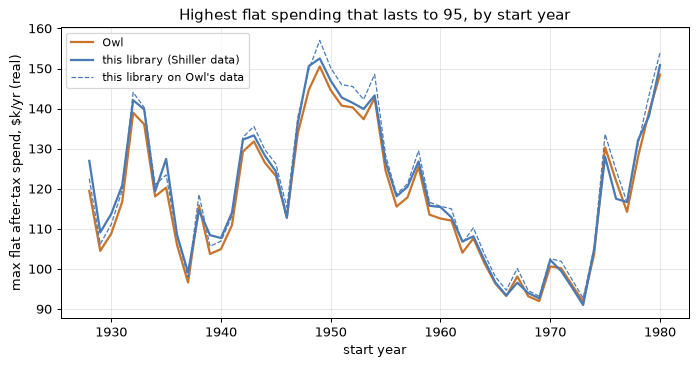

In [7]:
df = pd.concat([owl_spend, ours, ours_on_owl_data], axis=1)
df["diff $"] = df["this library"] - df["Owl"]
df["diff %"] = 100 * df["diff $"] / df["Owl"]

fig, ax = plt.subplots()
ax.plot(df.index, df["Owl"] / 1e3, label="Owl", lw=1.8, color="#c8742c")
ax.plot(df.index, df["this library"] / 1e3, label="this library (Shiller data)", lw=1.8, color="#4a7ab5")
ax.plot(df.index, df["this library, Owl's data"] / 1e3, label="this library on Owl's data",
        lw=1.0, ls="--", color="#4a7ab5")
ax.set_xlabel("start year"); ax.set_ylabel("max flat after-tax spend, $k/yr (real)")
ax.set_title("Highest flat spending that lasts to 95, by start year")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.show()

In [8]:
def summary(col):
    s = df[col]
    return {"worst start": int(s.idxmin()), "worst $": s.min(), "median $": s.median(),
            "best $": s.max(), "worst 4 starts": ", ".join(map(str, s.nsmallest(4).index))}

summ = pd.DataFrame({c: summary(c) for c in ["Owl", "this library", "this library, Owl's data"]}).T
summ[["worst $", "median $", "best $"]] = summ[["worst $", "median $", "best $"]].astype(float).round(0)
summ

,worst start,worst $,median $,best $,worst 4 starts
Owl,1973,91845.0,115803.0,150511.0,"1973, 1969, 1968, 1966"
this library,1973,90991.0,117499.0,152515.0,"1973, 1969, 1966, 1968"
"this library, Owl's data",1973,92712.0,118634.0,157007.0,"1973, 1969, 1968, 1966"


In [9]:
CTL = "this library, Owl's data"
w_owl, w_ours = df["Owl"].min(), df["this library"].min()
m_owl, m_ours = df["Owl"].median(), df["this library"].median()
w_ctl, m_ctl = df["this library, Owl's data"].min(), df["this library, Owl's data"].median()
print(f"Worst cohort : Owl ${w_owl:,.0f} ({int(df['Owl'].idxmin())})   this library ${w_ours:,.0f} "
      f"({int(df['this library'].idxmin())})   diff ${w_ours - w_owl:+,.0f} ({100 * (w_ours / w_owl - 1):+.1f}%)")
print(f"Median cohort: Owl ${m_owl:,.0f}   this library ${m_ours:,.0f}   diff ${m_ours - m_owl:+,.0f} "
      f"({100 * (m_ours / m_owl - 1):+.1f}%)")
print(f"Same-data control: worst ${w_ctl:,.0f} ({100 * (w_ctl / w_owl - 1):+.1f}% vs Owl), "
      f"median ${m_ctl:,.0f} ({100 * (m_ctl / m_owl - 1):+.1f}% vs Owl)")
print(f"Per-cohort difference, this library vs Owl: median {df['diff %'].median():+.1f}%, "
      f"range {df['diff %'].min():+.1f}% to {df['diff %'].max():+.1f}%")
ctl_pct = 100 * (df[CTL] / df["Owl"] - 1)
print(f"Per-cohort difference, same data vs Owl: median {ctl_pct.median():+.1f}%, "
      f"range {ctl_pct.min():+.1f}% to {ctl_pct.max():+.1f}%")
print(f"Rank correlation across cohorts: {df['Owl'].corr(df['this library'], method='spearman'):.2f} "
      f"(same data: {df['Owl'].corr(df[CTL], method='spearman'):.2f})")

Worst cohort : Owl $91,845 (1973)   this library $90,991 (1973)   diff $-854 (-0.9%)
Median cohort: Owl $115,803   this library $117,499   diff $+1,696 (+1.5%)
Same-data control: worst $92,712 (+0.9% vs Owl), median $118,634 (+2.4% vs Owl)
Per-cohort difference, this library vs Owl: median +1.6%, range -3.7% to +6.3%
Per-cohort difference, same data vs Owl: median +2.5%, range +0.9% to +4.3%
Rank correlation across cohorts: 0.99 (same data: 1.00)


In [10]:
df.round(0).astype("Int64").assign(**{"diff %": df["diff %"].round(1)})

,Owl,this library,"this library, Owl's data",diff $,diff %
1928,119449,126959,122522,7510,6.3
1929,104502,109119,106219,4617,4.4
1930,108802,113727,111096,4925,4.5
1931,116730,120880,119641,4150,3.6
1932,138985,142084,144043,3099,2.2
1933,136072,139807,140271,3735,2.7
1934,118095,119379,121008,1284,1.1
1935,120289,127429,123450,7140,5.9
1936,105948,108478,108124,2529,2.4
1937,96614,99097,98053,2482,2.6


## Reading the result

- **Where they agree.** Both tools rank the same start years worst (the late 1960s and early
  1970s, when a decade of high inflation met the bridge years), and the worst-cohort and
  median spending levels are within a few percent. The cohort rankings are almost identical.
- **Data accounts for the scatter.** With each tool on its own returns, the per-cohort gap
  moves around from year to year. Run on Owl's return table, this library ranks the cohorts
  the same way Owl does and the gap becomes a steady offset. Shiller's January-to-January
  monthly-average prices and duration-7 bond proxy give different individual years than
  calendar-year S&P and T-note returns.
- **The steady offset is the model.** On identical returns this library finds slightly
  *more* spendable money than Owl, by a few percent at most. Known differences: Owl taxes
  bond interest in the taxable account every year, this library does not tax
  taxable-account dividends or interest (both compute the taxable share of Social Security
  from provisional income); Owl pays Social Security in arrears
  and handles ages by month; the two tools use different within-year timing. Owl also
  optimizes the withdrawal order, which pushes the other way, so the net gap is small.

The cross-check is evidence that the engine's cash-flow and tax plumbing is sound for this
kind of household. It is not evidence that either tool's assumptions fit a particular
person.